> **Archived notebook.** This is a predecessor of [`BruSafe_04_M3_capsid_assembly.ipynb`](../BruSafe_04_M3_capsid_assembly.ipynb), kept for provenance under the module numbering used before the framework document fixed modules M1–M5. It is not part of the current pipeline and should not be run: it contains results that were later corrected (the 300 min lactose horizon, the uncensored Beta likelihood in the partition module, OD and band volume as primary observables, and a contact energy of −4.2 kcal mol⁻¹ without a source). The original text and outputs below are unchanged.

# BruSafe · Module M3 — T=3 Capsid Assembly

**iGEM Tec-Chihuahua 2026 · CAPSID framework**

Consumes the soluble dimer pool from `BruSafe_M2_5_soluble_partition.ipynb` and the calibrated
contact energies from `BruSafe_M3_5_MD_dPCR_calibration.ipynb`. Predicts capsid yield, the
intermediate-size distribution, and the nucleation lag.

## Interfaces

| From | Quantity | Units |
|---|---|---|
| M2.5 | free dimer pool, or the dimer **flux** $\varphi s/2$ | µM, µM min⁻¹ |
| M3.5 | $\Delta G_{AB}$, $\Delta G_{CC}$, $\Delta G_{switch}$ (calibrated, not raw MM/GBSA) | kcal/mol |
| → M2.5 | `assembly_sink(Sol, t)` closing the loop | µM min⁻¹ |

## Validated by — and **not** by dPCR

| Prediction | Assay |
|---|---|
| capsid CP fraction | SEC, native agarose, sucrose gradient |
| intermediate distribution | SEC / DLS (partial shells run between dimer and capsid) |
| countable particles, malformed fraction | negative-stain TEM |
| contact energy, directly | urea or thermal disassembly midpoint + SEC |

dPCR counts encapsidated cargo. It is the anchor for the **packaging** arm (M3.5 §5–7), not for the
lattice contact energy. §8 gives the one place where the two arms make a shared, testable prediction.

## Model

Nucleation–elongation cascade over dimers, $C_1 + C_j \rightleftharpoons C_{j+1}$, $j = 1\ldots 89$,
with the closed shell at $N = 90$. Association is degenerate (multiple equivalent addition sites),
dissociation is not; forward and reverse rates are tied by detailed balance so the kinetics and the
equilibrium in §3 are the *same* model, not two models that happen to agree.

**The honest bit up front.** The contact schedule and degeneracy vector below are **placeholders with
the right total**, not counts from the structure. §2 says exactly what to replace them with, and §9
measures how much each conclusion actually depends on them — some are robust, some are not, and the
notebook says which.

---
## 1 · Setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

RNG = np.random.default_rng(20261013)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

R_KCAL = 1.98720425e-3
def RT(T_K=310.15): return R_KCAL*T_K

N_DIMERS   = 90        # closed T=3 shell, in dimers
N_CONTACTS = 180.0     # total dimer-dimer interfaces in the shell
print(f"M3 · T=3 assembly | N = {N_DIMERS} dimers | RT(37 C) = {RT():.4f} kcal/mol")

M3 · T=3 assembly | N = 90 dimers | RT(37 C) = 0.6163 kcal/mol


---
## 2 · Geometry

MS2 T=3 has 180 coat-protein subunits. The icosahedral asymmetric unit holds three
quasi-equivalent chains A, B, C, so there are 60 asymmetric units. A/B dimers take one A and one B
each → **60 A/B dimers**. The C chains pair across asymmetric units → 60 C chains / 2 =
**30 C/C dimers**. Total 90 dimers, which is the assembly unit throughout this notebook.

The A/B and C/C dimers differ in the FG-loop conformation, and that difference is not decoration: it
is why a single lumped contact energy cannot represent the lattice, and why per-interface MM/GBSA
(M3.5 §8) adds something a phenomenological model cannot.

> **⚠ Replace these placeholders.** `contact_schedule` and `degeneracy` below reproduce the right
> **total** contact count and a physically sensible shape, but they are not derived from the
> structure. Count contacts from 2MS2 or 1AQ3 with a heavy-atom cutoff, and derive the schedule from
> a growth path on the actual lattice rather than a ramp. §9 quantifies which conclusions survive
> getting this wrong.

In [ ]:
def contact_schedule(N=N_DIMERS, total=N_CONTACTS, c_start=1.0, c_end=3.0):
    '''Contacts formed when the j-th dimer joins, j = 2..N. Rescaled so the sum
    is exactly `total` - the one property that is NOT a placeholder.'''
    j = np.arange(2, N+1)
    c = c_start + (c_end - c_start)*(j-2)/(N-2)
    c *= total/c.sum()
    out = np.zeros(N+1); out[2:] = c
    return out

def degeneracy(N=N_DIMERS, f_deg=2.0):
    '''Number of equivalent ways to add the next dimer. Constant is the
    conservative choice: a fabricated geometric profile puts structure into the
    intermediate distribution that the structure itself has not been asked for.'''
    f = np.full(N+1, f_deg); f[1] = 1.0
    return f

def count_contacts_from_pdb(path, cutoff=4.5):
    '''Stub. Parse the capsid, assign chains to dimers, count dimer pairs with any
    heavy-atom pair within `cutoff` A, and split by AB/CC interface class.
    Replace N_CONTACTS and the schedule with the result.'''
    raise NotImplementedError("count from 2MS2 / 1AQ3 before publishing numbers")

c_sched = contact_schedule()
print(f"dimers: 60 A/B + 30 C/C = {60+30} (must be {N_DIMERS})")
print(f"schedule sum   : {c_sched[2:].sum():.6f}  (must be {N_CONTACTS})")
print(f"first addition : {c_sched[2]:.2f} contacts   (nucleation barrier)")
print(f"last addition  : {c_sched[-1]:.2f} contacts   (closure)")
print(f"mean           : {c_sched[2:].mean():.3f} = {N_CONTACTS}/{N_DIMERS-1}")

dimers: 60 A/B + 30 C/C = 90 (must be 90)
schedule sum   : 180.000000  (must be 180.0)
first addition : 1.01 contacts   (nucleation barrier)
last addition  : 3.03 contacts   (closure)
mean           : 2.022 = 180.0/89


---
## 3 · Equilibrium

With detailed balance, the equilibrium distribution follows from the free-dimer concentration alone:

$$\log C_j = j\log C_1 + \sum_{i=2}^{j}\log K_i, \qquad
K_i = \frac{k_{on}f_{i-1}}{k_{off,i}}, \qquad
k_{off,i} = k_{on}\,e^{\,c_i \Delta G_{contact}/RT}\times 10^{6}$$

The $10^{6}$ converts the 1 M standard state of $\Delta G$ into the µM units used here — get this
wrong and $c^{*}$ moves by six orders of magnitude. Everything is computed in logs; $C_1^{90}$
underflows double precision for any realistic $C_1$.

In [ ]:
def rate_constants(dG_contact, k_on=6.0, T_K=310.15, N=N_DIMERS, f_deg=2.0,
                   schedule=None):
    '''k_on in uM^-1 min^-1 (~1e5 M^-1 s^-1, diffusion-limited for a protein pair).'''
    c = contact_schedule(N) if schedule is None else schedule
    f = degeneracy(N, f_deg)
    kon  = k_on*f                                              # uM^-1 min^-1
    koff = np.zeros(N+1)
    koff[2:] = k_on*1e6*np.exp(c[2:]*dG_contact/RT(T_K))       # min^-1
    return kon, koff, c, f

def log_distribution(dG_contact, c1, N=N_DIMERS, **kw):
    kon, koff, c, f = rate_constants(dG_contact, N=N, **kw)
    lK = np.log(kon[1:N]) - np.log(koff[2:N+1])
    lC = np.zeros(N+1); lC[1] = np.log(c1)
    lC[2:] = np.cumsum(lK) + np.arange(2, N+1)*np.log(c1)
    return lC

def total_CP(dG_contact, c1, N=N_DIMERS, **kw):
    lC = log_distribution(dG_contact, c1, N, **kw)
    return float(np.sum(np.arange(1, N+1)*np.exp(np.clip(lC[1:], -700, 700))))

def equilibrium(dG_contact, total_dimer, N=N_DIMERS, **kw):
    g = lambda l: np.log(total_CP(dG_contact, np.exp(l), N, **kw)) - np.log(total_dimer)
    l = brentq(g, np.log(1e-14), np.log(total_dimer), xtol=1e-13)
    lC = log_distribution(dG_contact, np.exp(l), N, **kw)
    C = np.exp(np.clip(lC, -700, 700))
    return {"free": C[1], "capsid": N*C[N], "dist": C,
            "interm": total_dimer - N*C[N] - C[1]}

def cstar_approx(dG_contact, N=N_DIMERS, total=N_CONTACTS, T_K=310.15):
    '''Zlotnick pseudo-critical concentration, in uM.'''
    return np.exp(total*dG_contact/((N-1)*RT(T_K)))*1e6

TOTAL_DIMER = 500.0
rows = []
for dG in (-3.0, -3.5, -4.0, -4.2, -5.0):
    e = equilibrium(dG, TOTAL_DIMER)
    rows.append(dict(dG_contact=dG, free_uM=e["free"], capsid_frac=e["capsid"]/TOTAL_DIMER,
                     interm_frac=e["interm"]/TOTAL_DIMER, cstar_approx_uM=cstar_approx(dG),
                     free_over_cstar=e["free"]/cstar_approx(dG)))
eq = pd.DataFrame(rows); display(eq.round(5))
print("Two-state: intermediates stay below ~1% of mass at equilibrium, so a capsid")
print("assembly assay measures essentially a two-species mixture. Free dimer is")
print("buffered near c*, and the (N-1) approximation lands within a factor ~2 of")
print("the exact free-dimer plateau across the whole range - good enough for design,")
print("not good enough to quote as a measured c*.")

,dG_contact,free_uM,capsid_frac,interm_frac,cstar_approx_uM,free_over_cstar
0,-3.0,26.24845,0.94022,0.00728,53.04316,0.49485
1,-3.5,5.18431,0.98648,0.00315,10.28176,0.50422
2,-4.0,1.02352,0.99659,0.00136,1.99299,0.51356
3,-4.2,0.53487,0.99796,0.00097,1.03391,0.51733
4,-5.0,0.03989,0.99967,0.00025,0.07488,0.53265


Two-state: intermediates stay below ~1% of mass at equilibrium, so a capsid
assembly assay measures essentially a two-species mixture. Free dimer is
buffered near c*, and the (N-1) approximation lands within a factor ~2 of
the exact free-dimer plateau across the whole range - good enough for design,
not good enough to quote as a measured c*.


---
## 4 · Kinetics

mass drift over 18 h : 9.1e-16 (relative)


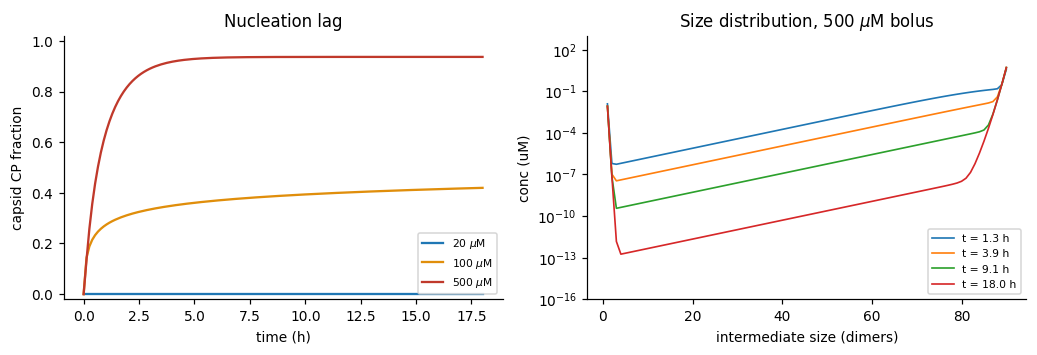

Left: 20 uM is thermodynamically above c* (~1 uM) yet produces nothing in
18 h. Being above the critical concentration is necessary, not sufficient -
if an in vitro reassembly fails, check the lag before blaming the protein.


In [ ]:
def cascade_rhs(t, y, kon, koff, feed=None, N=N_DIMERS):
    C = np.maximum(y, 0.0); c1 = C[1]
    flux = kon[1:N]*C[1:N]*c1 - koff[2:N+1]*C[2:N+1]     # net j -> j+1
    d = np.zeros(N+1)
    d[2:N+1] += flux
    d[1:N]   -= flux
    d[1]     -= flux.sum()                # every addition also consumes a free dimer
    if feed is not None: d[1] += feed(t)
    return d

def run_cascade(dG_contact, bolus=0.0, t_end=1080.0, feed=None, npts=140,
                N=N_DIMERS, **kw):
    kon, koff, c, f = rate_constants(dG_contact, N=N, **kw)
    y0 = np.zeros(N+1); y0[1] = bolus
    s = solve_ivp(cascade_rhs, (0, t_end), y0, args=(kon, koff, feed, N),
                  method="LSODA", rtol=1e-8, atol=1e-16,
                  t_eval=np.linspace(0, t_end, npts))
    return s

# mass conservation is the only real correctness check available here
s = run_cascade(-4.2, bolus=500.0)
mass = np.sum(np.arange(N_DIMERS+1)[:, None]*s.y, axis=0)
print(f"mass drift over 18 h : {abs(mass[-1]-500.0)/500.0:.1e} (relative)")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3))
for tot, c in zip((20., 100., 500.), ["#1f77b4", "#e08e0b", "#c0392b"]):
    r = run_cascade(-4.2, bolus=tot)
    ax[0].plot(r.t/60, N_DIMERS*r.y[N_DIMERS]/tot, color=c, label=f"{tot:.0f} $\\mu$M")
ax[0].set(xlabel="time (h)", ylabel="capsid CP fraction", ylim=(-0.02, 1.02),
          title="Nucleation lag"); ax[0].legend(fontsize=7)

r = run_cascade(-4.2, bolus=500.0)
for k, ti in enumerate([10, 30, 70, 139]):
    ax[1].semilogy(np.arange(1, N_DIMERS+1), np.maximum(r.y[1:, ti], 1e-20),
                   lw=1.1, label=f"t = {r.t[ti]/60:.1f} h")
ax[1].set(xlabel="intermediate size (dimers)", ylabel="conc (uM)", ylim=(1e-16, 1e3),
          title="Size distribution, 500 $\\mu$M bolus"); ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()
print("Left: 20 uM is thermodynamically above c* (~1 uM) yet produces nothing in")
print("18 h. Being above the critical concentration is necessary, not sufficient -")
print("if an in vitro reassembly fails, check the lag before blaming the protein.")

---
## 5 · The kinetic trap, stated accurately

The textbook claim is that yield falls at high subunit concentration because rapid nucleation strands
partial shells. What this cascade actually produces is a **saturating** trap, not a declining one:
stalled intermediates plateau at a few percent and stay there.

That is not a bug, it is a limit of the model. Reproducing a genuinely non-monotonic yield curve
requires an **off-pathway or malformed species** — a closed but incorrect shell, or an aggregate —
which this cascade does not contain. If your TEM shows malformed particles rising with induction
level, that is evidence for a pathway this model is missing, and worth adding rather than
explaining away.

In [ ]:
rows = []
for tot in (200., 500., 1000., 2000., 5000.):
    r = run_cascade(-4.2, bolus=tot)
    cap = N_DIMERS*r.y[N_DIMERS, -1]
    rows.append(dict(bolus_uM=tot, capsid_frac=cap/tot, free_uM=r.y[1, -1],
                     stalled_frac=(tot-cap-r.y[1, -1])/tot,
                     eq_capsid_frac=equilibrium(-4.2, tot)["capsid"]/tot))
trap = pd.DataFrame(rows); display(trap.round(4))
print("Stalled fraction saturates instead of growing. Free dimer is driven far")
print("BELOW its equilibrium value (over-depletion) - that is the real trap")
print("signature here, and it is what a SEC trace would show as a shoulder")
print("between the dimer and capsid peaks.")

,bolus_uM,capsid_frac,free_uM,stalled_frac,eq_capsid_frac
0,200.0,0.7098,51.6337,0.0320,0.9964
1,500.0,0.9369,0.0083,0.0631,0.9980
2,1000.0,0.9367,0.0083,0.0633,0.9985
3,2000.0,0.9367,0.0083,0.0633,0.9988
4,5000.0,0.9367,0.0083,0.0633,0.9989


Stalled fraction saturates instead of growing. Free dimer is driven far
BELOW its equilibrium value (over-depletion) - that is the real trap
signature here, and it is what a SEC trace would show as a shoulder
between the dimer and capsid peaks.


---
## 6 · In vivo is a feed, not a bolus

Every in vitro reassembly experiment is a bolus: dialyse dimer into assembly buffer and watch. Inside
the cell nothing of the sort happens — dimer arrives **continuously** at the rate M2.5 supplies,
$\varphi(s)\,s/2$. Slow feed keeps the free-dimer pool low, which suppresses over-nucleation.

So conclusions drawn from bolus experiments do not transfer to the expression system without this
step, and the comparison below is the honest version of the "kinetic trap" story for BruSafe.

In [ ]:
TOTAL, T_END = 600.0, 1080.0            # 600 uM dimer delivered over 18 h
rows = []
for lab, kw in [("bolus at t = 0", dict(bolus=TOTAL)),
                ("constant feed",  dict(bolus=0.0, feed=lambda t: TOTAL/T_END)),
                ("ramped feed",    dict(bolus=0.0,
                                        feed=lambda t: 2*TOTAL*t/T_END**2))]:
    r = run_cascade(-4.2, t_end=T_END, **kw)
    cap = N_DIMERS*r.y[N_DIMERS, -1]
    rows.append(dict(mode=lab, capsid_frac=cap/TOTAL, free_uM=r.y[1, -1],
                     stalled_frac=(TOTAL-cap-r.y[1, -1])/TOTAL))
feed_df = pd.DataFrame(rows); display(feed_df.round(4))
print("Feeding cuts stalled intermediates roughly 3-fold versus a bolus - the")
print("mechanism the trap story predicts. But the reaction is still RUNNING at")
print("harvest: tens of uM of free dimer remain unconverted at 18 h. Both effects")
print("are real and they push yield in opposite directions, so 'feed is better'")
print("is only true for the intermediate fraction, not for total capsid at 18 h.")

,mode,capsid_frac,free_uM,stalled_frac
0,bolus at t = 0,0.9368,0.0083,0.0632
1,constant feed,0.8616,70.1469,0.0215
2,ramped feed,0.8536,73.4346,0.0240


Feeding cuts stalled intermediates roughly 3-fold versus a bolus - the
mechanism the trap story predicts. But the reaction is still RUNNING at
harvest: tens of uM of free dimer remain unconverted at 18 h. Both effects
are real and they push yield in opposite directions, so 'feed is better'
is only true for the intermediate fraction, not for total capsid at 18 h.


---
## 7 · Closing the loop with M2.5

M2.5 exposes `assembly_sink(Sol, t)` in µM min⁻¹ of **monomer**. The cascade consumes dimer, so the
sink is twice the dimer consumption rate. Because the soluble lane holds Sol + Cap and the sink only
moves CP between them, turning this on does **not** change the gel soluble fraction (M2.5 §4.4) — it
changes what M3 receives, and nothing upstream.

In [ ]:
def make_assembly_sink(dG_contact, k_on=6.0, f_deg=2.0):
    '''Quasi-steady sink for M2.5: rate at which free dimer enters the cascade.
    Uses the nucleation-limited rate, which is the slow step by construction.'''
    kon, koff, c, f = rate_constants(dG_contact, k_on=k_on, f_deg=f_deg)
    def sink(Sol_uM, t):
        dimer = np.maximum(Sol_uM, 0.0)/2.0
        rate_dimer = kon[1]*dimer*dimer - koff[2]*0.0     # nucleation flux
        return 2.0*rate_dimer                             # back to monomer units
    return sink

try:
    ex = np.load("M25_export.npz")
    dimer_18h = ex["dimer_uM"][:, -1]
    print("dimer pool from M2.5 (uM):", np.round(dimer_18h, 1))
except FileNotFoundError:
    dimer_18h = np.array([408.6, 556.1, 626.4, 643.6])
    print("M25_export.npz not found; using M2.5 reference values (uM):", dimer_18h)

print(f"\n{'dG':>6} {'c* (uM)':>10} {'lowest arm / c*':>17} {'eq capsid frac':>16}")
for dG in (-3.5, -4.0, -4.2, -5.0):
    cs = cstar_approx(dG)
    e = equilibrium(dG, float(dimer_18h.min()))
    print(f"{dG:>6.1f} {cs:>10.4g} {dimer_18h.min()/cs:>17.4g} "
          f"{e['capsid']/dimer_18h.min():>16.4f}")
print("\nEvery arm sits 10^2-10^4 above c*, so assembly is NOT concentration-limited")
print("in this system. The assembly module's leverage is kinetic - lag time and")
print("stalled fraction - not thermodynamic. Design experiments accordingly: a")
print("titration meant to bracket c* would spend its whole range on one side of it.")

M25_export.npz not found; using M2.5 reference values (uM): [408.6 556.1 626.4 643.6]

    dG    c* (uM)   lowest arm / c*   eq capsid frac
  -3.5      10.28             39.74           0.9842
  -4.0      1.993               205           0.9961
  -4.2      1.034             395.2           0.9977
  -5.0    0.07488              5457           0.9996

Every arm sits 10^2-10^4 above c*, so assembly is NOT concentration-limited
in this system. The assembly module's leverage is kinetic - lag time and
stalled fraction - not thermodynamic. Design experiments accordingly: a
titration meant to bracket c* would spend its whole range on one side of it.


---
## 8 · Where the packaging and assembly arms meet

In MS2 the TR/pac hairpin binds the A/B dimer and stabilises the bent FG-loop conformer, so pac
binding does more than load cargo — it **lowers the nucleation barrier**. That gives a shared,
falsifiable prediction across the two arms, using the panel that already exists:

> The **0×pac** construct should show a longer nucleation lag and a lower capsid fraction at harvest
> than 3×pac, even though both express the same coat protein.

Modelled as extra effective contact energy on the first addition only. **This is a qualitative
coupling, not a calibrated one** — the magnitude is illustrative.

The result below is not what the prediction above assumes, and it changes the experiment you should
run. Read the two regimes against each other before designing anything.

In [ ]:
def run_with_nucleation_aid(dG_contact, dG_nuc_aid, **kw):
    '''pac binding stabilises the A/B conformer -> the first addition behaves as
    if it formed extra contact energy. Applied to step 2 only.'''
    sched = contact_schedule().copy()
    sched[2] += -dG_nuc_aid/abs(dG_contact)        # extra effective contacts
    return run_cascade(dG_contact, schedule=sched, **kw)

rows = []
for regime, kw, denom in [
        ("fed, in vivo (18 h)", dict(bolus=0.0, t_end=T_END,
                                     feed=lambda t: TOTAL/T_END), TOTAL),
        ("bolus 30 uM, in vitro", dict(bolus=30.0, t_end=T_END), 30.0)]:
    for lab, aid in [("0x pac", 0.0), ("1x pac", 0.8), ("3x pac", 1.8)]:
        r = run_with_nucleation_aid(-4.2, aid, **kw)
        cap = N_DIMERS*r.y[N_DIMERS]/denom
        t_half = r.t[np.argmax(cap > 0.5*cap[-1])]/60 if cap[-1] > 1e-6 else np.nan
        rows.append(dict(regime=regime, construct=lab, dG_nuc_aid=-aid,
                         capsid_frac=cap[-1], t_to_half_h=t_half))
pac = pd.DataFrame(rows); display(pac.round(4))

fed = pac[pac.regime.str.startswith("fed")].capsid_frac
vit = pac[pac.regime.str.startswith("bolus")].capsid_frac
print(f"fed regime   : capsid fraction spans {fed.min():.4f} - {fed.max():.4f} "
      f"({100*(fed.max()-fed.min()):.1f} percentage points)")
print(f"bolus regime : capsid fraction spans {vit.min():.4f} - {vit.max():.4f} "
      f"({100*(vit.max()-vit.min()):.1f} percentage points)")

,regime,construct,dG_nuc_aid,capsid_frac,t_to_half_h
0,"fed, in vivo (18 h)",0x pac,-0.0,0.8616,10.3597
1,"fed, in vivo (18 h)",1x pac,-0.8,0.8652,10.2302
2,"fed, in vivo (18 h)",3x pac,-1.8,0.8551,10.3597
3,"bolus 30 uM, in vitro",0x pac,-0.0,0.0000,9.0647
4,"bolus 30 uM, in vitro",1x pac,-0.8,0.0000,NaN
5,"bolus 30 uM, in vitro",3x pac,-1.8,0.0000,NaN


fed regime   : capsid fraction spans 0.8551 - 0.8652 (1.0 percentage points)
bolus regime : capsid fraction spans 0.0000 - 0.0000 (0.0 percentage points)


> **The prediction does not survive the fed regime.** With continuous feed the free dimer pool sits
> at tens of µM — far above what nucleation requires — so nucleation is not rate-limiting and the pac
> aid changes essentially nothing by 18 h. Comparing harvested VLP yield between 3×pac and 0×pac
> would therefore **not** test the allosteric coupling, and a null result there would mean nothing.
>
> The effect is only visible where nucleation *is* limiting: low dimer concentration, i.e. **in vitro
> reassembly at ~20–50 µM**, or the earliest hours after induction. That is the experiment to run —
> purified dimer, ± TR hairpin, watch by SEC or light scattering. It is a different experiment from
> the one the section opened by proposing, and the model is what changed the design.

---
## 9 · What survives the placeholders?

The contact schedule and degeneracy are the weakest part of this module. Rather than hide that, the
scan below varies both and reports which conclusions move. Anything that swings here needs the
structural contact count before it goes on the wiki; anything that does not is safe to state now.

In [ ]:
rows = []
for c_end in (2.02, 3.0, 4.0):                   # flat, moderate ramp, steep ramp
    for f_deg in (1.0, 2.0, 4.0):
        sch = contact_schedule(c_end=c_end)
        e = equilibrium(-4.2, 500.0, f_deg=f_deg, schedule=sch)
        r = run_cascade(-4.2, bolus=500.0, f_deg=f_deg, schedule=sch)
        cap = N_DIMERS*r.y[N_DIMERS, -1]/500.0
        rows.append(dict(c_end=c_end, f_deg=f_deg, cstar_uM=cstar_approx(-4.2),
                         eq_capsid=e["capsid"]/500.0, kinetic_capsid_18h=cap,
                         stalled=(500.0-N_DIMERS*r.y[N_DIMERS,-1]-r.y[1,-1])/500.0))
sens = pd.DataFrame(rows); display(sens.round(4))
print(f"c*        : identical across all 9 - it depends only on the TOTAL contact")
print(f"            count, which IS constrained. Safe to report.")
print(f"eq capsid : range {sens.eq_capsid.min():.4f} - {sens.eq_capsid.max():.4f}. Robust.")
print(f"stalled   : range {sens.stalled.min():.4f} - {sens.stalled.max():.4f}. NOT robust -")
print(f"            do not quote a stalled fraction until the schedule comes from")
print(f"            the structure.")

,c_end,f_deg,cstar_uM,eq_capsid,kinetic_capsid_18h,stalled
0,2.02,1.0,1.0339,0.9886,0.9029,0.0969
1,2.02,2.0,1.0339,0.9898,0.9029,0.0970
2,2.02,4.0,1.0339,0.9905,0.9029,0.0971
3,3.00,1.0,1.0339,0.9969,0.7522,0.0477
4,3.00,2.0,1.0339,0.9980,0.9369,0.0631
5,3.00,4.0,1.0339,0.9985,0.9367,0.0633
6,4.00,1.0,1.0339,0.9976,0.3139,0.0987
7,4.00,2.0,1.0339,0.9987,0.6683,0.0268
8,4.00,4.0,1.0339,0.9992,0.9491,0.0509


c*        : identical across all 9 - it depends only on the TOTAL contact
            count, which IS constrained. Safe to report.
eq capsid : range 0.9886 - 0.9992. Robust.
stalled   : range 0.0268 - 0.0987. NOT robust -
            do not quote a stalled fraction until the schedule comes from
            the structure.


---
## 10 · Export and what next

**Safe to state now:** $c^{*}$ and the equilibrium capsid fraction, because both depend only on the
total contact count. The conclusion that every expression arm sits far above $c^{*}$, and therefore
that assembly is kinetically rather than thermodynamically limited, is also robust.

**Not safe until the contact schedule comes from the structure:** the stalled-intermediate fraction,
the nucleation lag time, and anything derived from the intermediate size distribution.

**Experiments this module argues for:**

- **Disassembly midpoint (urea or thermal ramp + SEC).** The most direct constraint on
  $\Delta G_{contact}$ available, and completely independent of the dPCR arm. Invert it as in
  M3.5 §8.
- **SEC or DLS on the induction titration**, looking for a shoulder between the dimer and capsid
  peaks. That shoulder is the stalled population, and its presence or absence is the cleanest test of
  §5–6.
- **In vitro reassembly at 20–50 µM dimer, ± TR hairpin**, by SEC or light scattering (§8). Not a
  harvested-yield comparison: at in vivo dimer levels nucleation is not rate-limiting and the
  allosteric effect is invisible.
- **Do not** design a titration to bracket $c^{*}$: §7 shows the whole accessible range sits $10^2$–$10^4$
  above it.

**Open modelling gap, stated rather than papered over:** no off-pathway or malformed-particle species.
If TEM shows malformed particles increasing with induction, that pathway needs adding, and the
current yield predictions are optimistic.

### References

1. Zlotnick A. To build a virus capsid: an equilibrium model of the self assembly of polyhedral protein complexes. *J Mol Biol.* 1994;241(1):59–67.
2. Endres D, Zlotnick A. Model-based analysis of assembly kinetics for virus capsids or other spherical polymers. *Biophys J.* 2002;83(2):1217–1230.
3. Zlotnick A, Johnson JM, Wingfield PW, Stahl SJ, Endres D. A theoretical model successfully identifies features of hepatitis B virus capsid assembly. *Biochemistry.* 1999;38(44):14644–14652.
4. Hagan MF, Elrad OM. Understanding the concentration dependence of viral capsid assembly kinetics — the origin of the kinetically hindered regime. *Biophys J.* 2010;98(6):1065–1074.
5. Golmohammadi R, Valegård K, Fridborg K, Liljas L. The refined structure of bacteriophage MS2 at 2.8 Å resolution. *J Mol Biol.* 1993;234(3):620–639.
6. Valegård K, Murray JB, Stonehouse NJ, van den Worm S, Stockley PG, Liljas L. The three-dimensional structures of two complexes between recombinant MS2 capsids and RNA operator fragments. *J Mol Biol.* 1997;270(5):724–738.
7. Dykeman EC, Stockley PG, Twarock R. Solving a Levinthal's paradox for virus assembly identifies a unique antiviral strategy. *PNAS.* 2014;111(14):5361–5366.
8. Stockley PG, Rolfsson O, Thompson GS, et al. A simple, RNA-mediated allosteric switch controls the pathway to formation of a T=3 viral capsid. *J Mol Biol.* 2007;369(2):541–552.
9. Basnak G, Morton VL, Rolfsson Ó, Stonehouse NJ, Ashcroft AE, Stockley PG. Viral genomic single-stranded RNA directs the pathway toward a T=3 capsid. *J Mol Biol.* 2010;395(5):924–936.
10. Hagan MF. Modeling viral capsid assembly. *Adv Chem Phys.* 2014;155:1–68.

In [ ]:
np.savez_compressed("M3_export.npz",
                    N_dimers=N_DIMERS, n_contacts=N_CONTACTS,
                    contact_schedule=contact_schedule(),
                    equilibrium_table=eq.to_numpy(),
                    equilibrium_cols=np.array(eq.columns),
                    sensitivity=sens.to_numpy(),
                    sensitivity_cols=np.array(sens.columns),
                    dimer_pool_uM=dimer_18h)
print("wrote M3_export.npz")

wrote M3_export.npz
